# Домашнее задание 5. Построение естественного кубического сплайна
**Колпакова Дарья Сергеевна, группа J3112, ИСУ 501390**

**Вариант 11**
Функция 11 варианта: $f(x) = \frac{1}{3} + \cos(10 + 2.3^{|x|})$ на отрезке $[-1; 2.5]$.
Так как функция содержит модуль $|x|$, она не является дважды дифференцируемой в точке $x=0$, поэтому возьму следующую функцию (вариант 12).

**Вариант 12**
Функция: $f(x) = 2.5 \exp(\frac{x}{3} + 0.02) \cos(2x)$ на отрезке $[-2; 2]$.
Эта функция является гладкой на заданном отрезке.

## Построение системы для сплайна
Нам нужно построить естественный кубический сплайн по 4-м точкам.
Разобьем отрезок $[-2; 2]$ на 3 равные части.
Точки (узлы): $x_0 = -2$, $x_1 = -2/3$, $x_2 = 2/3$, $x_3 = 2$.
Шаг $h = x_{i} - x_{i-1} = 4/3$.

Сплайн на каждом подотрезке $[x_{i-1}, x_i]$ имеет вид:
$S_i(x) = a_i + b_i(x - x_i) + c_i(x - x_i)^2 + d_i(x - x_i)^3$

Для естественного сплайна граничные условия (вторые производные на концах равны нулю): $S''(x_0) = 0$, $S''(x_3) = 0$.
Обозначим $M_i = S''(x_i)$. Тогда $M_0 = 0$ и $M_3 = 0$.
Система уравнений для внутренних моментов $M_1$ и $M_2$:
$\frac{h}{6}M_{i-1} + \frac{2h}{3}M_i + \frac{h}{6}M_{i+1} = \frac{f_{i+1} - 2f_i + f_{i-1}}{h}$

Для $i=1$: $\frac{h}{6}M_0 + \frac{2h}{3}M_1 + \frac{h}{6}M_2 = \frac{f_2 - 2f_1 + f_0}{h}$
Для $i=2$: $\frac{h}{6}M_1 + \frac{2h}{3}M_2 + \frac{h}{6}M_3 = \frac{f_3 - 2f_2 + f_1}{h}$

Учитывая $M_0 = 0$ и $M_3 = 0$, получаем систему $2 \times 2$:
$4M_1 + M_2 = \frac{6}{h^2}(f_2 - 2f_1 + f_0)$
$M_1 + 4M_2 = \frac{6}{h^2}(f_3 - 2f_2 + f_1)$

Далее решим эту систему программно и найдем коэффициенты сплайна.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Функция 12 варианта
def f(x):
    return 2.5 * np.exp(x/3 + 0.02) * np.cos(2*x)

# Узлы интерполяции (4 точки)
x_nodes = np.linspace(-2, 2, 4)
y_nodes = f(x_nodes)
h = x_nodes[1] - x_nodes[0]

print("Узлы x:", np.round(x_nodes, 4))
print("Значения f(x):", np.round(y_nodes, 4))
print("Шаг h:", round(h, 4))

# Вычисление правых частей системы
rhs1 = (6 / h**2) * (y_nodes[2] - 2*y_nodes[1] + y_nodes[0])
rhs2 = (6 / h**2) * (y_nodes[3] - 2*y_nodes[2] + y_nodes[1])

# Матрица системы
A = np.array([
    [4, 1],
    [1, 4]
])
b = np.array([rhs1, rhs2])

# Решение системы (находим M1 и M2)
M_inner = np.linalg.solve(A, b)
M = np.array([0, M_inner[0], M_inner[1], 0]) # Добавляем M0=0 и M3=0

print("\nМоменты M:", np.round(M, 4))

# Вычисление коэффициентов a, b, c, d для каждого из 3-х отрезков
# Формулы для представления S_i(x) = a_i + b_i(x - x_i) + c_i(x - x_i)^2 + d_i(x - x_i)^3
# где x in [x_{i-1}, x_i]
a = y_nodes[1:]
c = M[1:] / 2
d = (M[1:] - M[:-1]) / (6 * h)
b = (y_nodes[1:] - y_nodes[:-1]) / h + h * (2 * M[1:] + M[:-1]) / 6

print("\nКоэффициенты сплайнов для 3-х отрезков:")
for i in range(3):
    print(f"Отрезок [{x_nodes[i]:.2f}, {x_nodes[i+1]:.2f}]: a={a[i]:.4f}, b={b[i]:.4f}, c={c[i]:.4f}, d={d[i]:.4f}")

# Функция для вычисления значения сплайна
def spline_eval(x_val):
    if x_val < x_nodes[1]:
        i = 0
    elif x_val < x_nodes[2]:
        i = 1
    else:
        i = 2
    dx = x_val - x_nodes[i+1]
    return a[i] + b[i]*dx + c[i]*dx**2 + d[i]*dx**3

# Векторизация функции сплайна для удобства построения графика
spline_eval_vec = np.vectorize(spline_eval)

Узлы x: [-2.     -0.6667  0.6667  2.    ]
Значения f(x): [-0.8559  0.4804  0.7493 -3.2471]
Шаг h: 1.3333

Моменты M: [ 0.0000e+00 -1.1000e-03 -3.5985e+00  0.0000e+00]

Коэффициенты сплайнов для 3-х отрезков:
Отрезок [-2.00, -0.67]: a=0.4804, b=1.0018, c=-0.0005, d=-0.0001
Отрезок [-0.67, 0.67]: a=0.7493, b=-1.3979, c=-1.7993, d=-0.4497
Отрезок [0.67, 2.00]: a=-3.2471, b=-3.7970, c=0.0000, d=0.4498


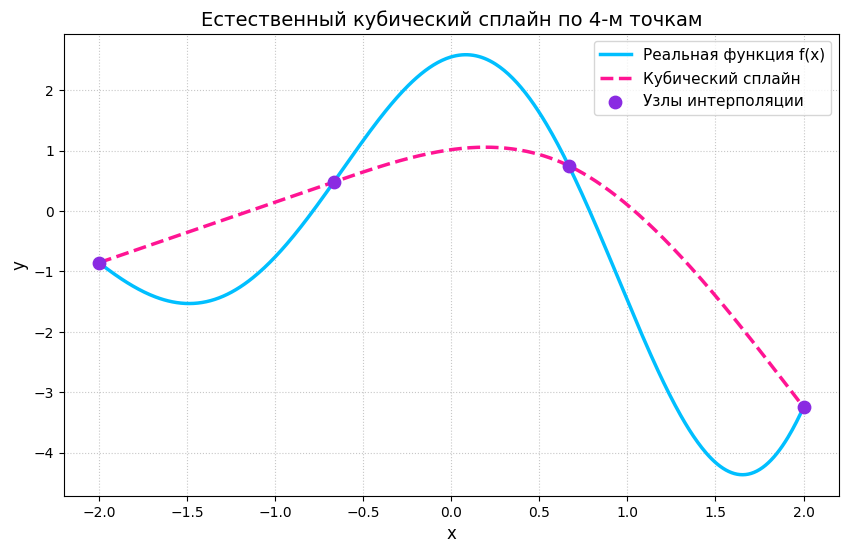

In [4]:
# Построение графиков
x_dense = np.linspace(-2, 2, 500)
y_exact = f(x_dense)
y_spline = spline_eval_vec(x_dense)

plt.figure(figsize=(10, 6))

color_exact = '#00BFFF'
color_spline = '#FF1493'
color_nodes = '#8A2BE2'

plt.plot(x_dense, y_exact, label='Реальная функция f(x)', color=color_exact, linewidth=2.5)
plt.plot(x_dense, y_spline, label='Кубический сплайн', color=color_spline, linestyle='--', linewidth=2.5)
plt.scatter(x_nodes, y_nodes, color=color_nodes, s=80, zorder=5, label='Узлы интерполяции')

plt.title('Естественный кубический сплайн по 4-м точкам', fontsize=14)
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)

plt.show()